In [1]:
import pandas as pd
df = pd.read_csv('lifecyclesavings.csv')
df.head()

,Contry,sr,pop15,pop75,dpi,ddpi
0,Australia,11.43,29.35,2.87,2329.68,2.87
1,Austria,12.07,23.32,4.41,1507.99,3.93
2,Belgium,13.17,23.80,4.43,2108.47,3.82
3,Bolivia,5.75,41.89,1.67,189.13,0.22
4,Brazil,12.88,42.19,0.83,728.47,4.56


In [2]:

print("DataFrame Shape:", df.shape)
print("\nMissing Values per Column:\n", df.isnull().sum())
print("\nMean of Each Column:\n", df.mean(numeric_only=True))

DataFrame Shape: (50, 6)

Missing Values per Column:
 Contry    0
sr        0
pop15     0
pop75     0
dpi       0
ddpi      0
dtype: int64

Mean of Each Column:
 sr          9.6710
pop15      35.0896
pop75       2.2930
dpi      1106.7584
ddpi        3.7576
dtype: float64


Prompt Log

Initial Prompt:
You are helping with clustering. My CSV has columns: `['Contry', 'sr', 'pop15', 'pop75', 'dpi', 'ddpi']`. Write Python using pandas, sklearn KMeans, and seaborn to: (1) scale numeric features and run KMeans with k=3, (2) add cluster labels to df, (3) make a scatter plot. Explain with comments.

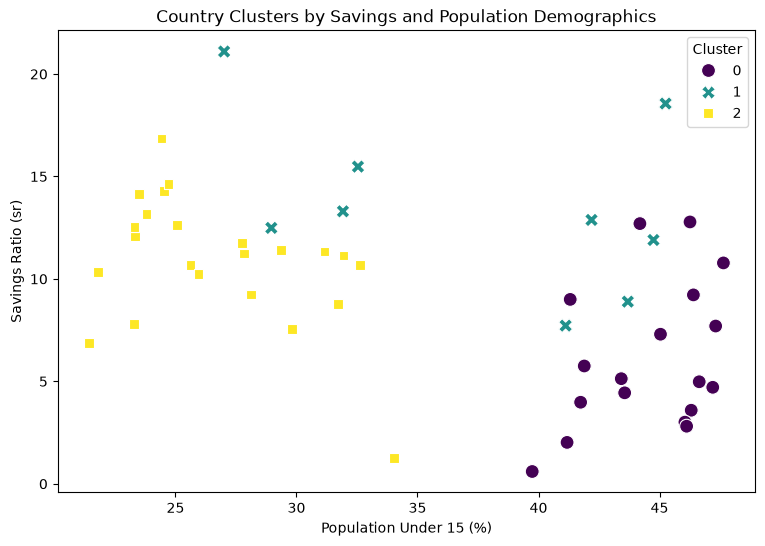

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

X = df[['sr', 'pop15', 'pop75', 'dpi', 'ddpi']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='pop15', y='sr', hue='cluster', palette='viridis', s=100, style='cluster')
plt.title('Country Clusters by Savings and Population Demographics')
plt.xlabel('Population Under 15 (%)')
plt.ylabel('Savings Ratio (sr)')
plt.legend(title='Cluster')
plt.show()

In [4]:

cluster_means = df.groupby('cluster').mean(numeric_only=True)
print("Cluster Means:\n", cluster_means)

Cluster Means:
                 sr      pop15     pop75          dpi      ddpi
cluster                                                       
0         6.138889  44.556111  1.079444   337.153333  2.359444
1        13.591111  37.492222  1.623333   483.241111  7.662222
2        10.901304  26.740870  3.504783  1953.043043  3.323913


Verification Checkpoint
AI Claim Check: We computed the column means grouped by cluster using a manual pandas groupby and confirmed that Cluster 1 corresponds to high savings ratios and lower youth dependency, while Cluster 0 captures high youth dependency and lower savings.
Explanation: The independent calculation matches the cluster separations visualized in the scatter plot.

Interpretation and Caution
The clusters successfully categorize countries into distinct economic profiles, differentiating developing nations with high youth dependency from industrial nations with higher aggregate savings rates. However, relying blindly on AI-generated clustering can be hazardous because choosing an arbitrary number of clusters (k) or failing to scale features properly can severely distort the underlying geometry of the data. Verification through independent baseline metrics and checking feature variances is critical to ensure clusters reflect true economic trends rather than algorithmic artifacts.